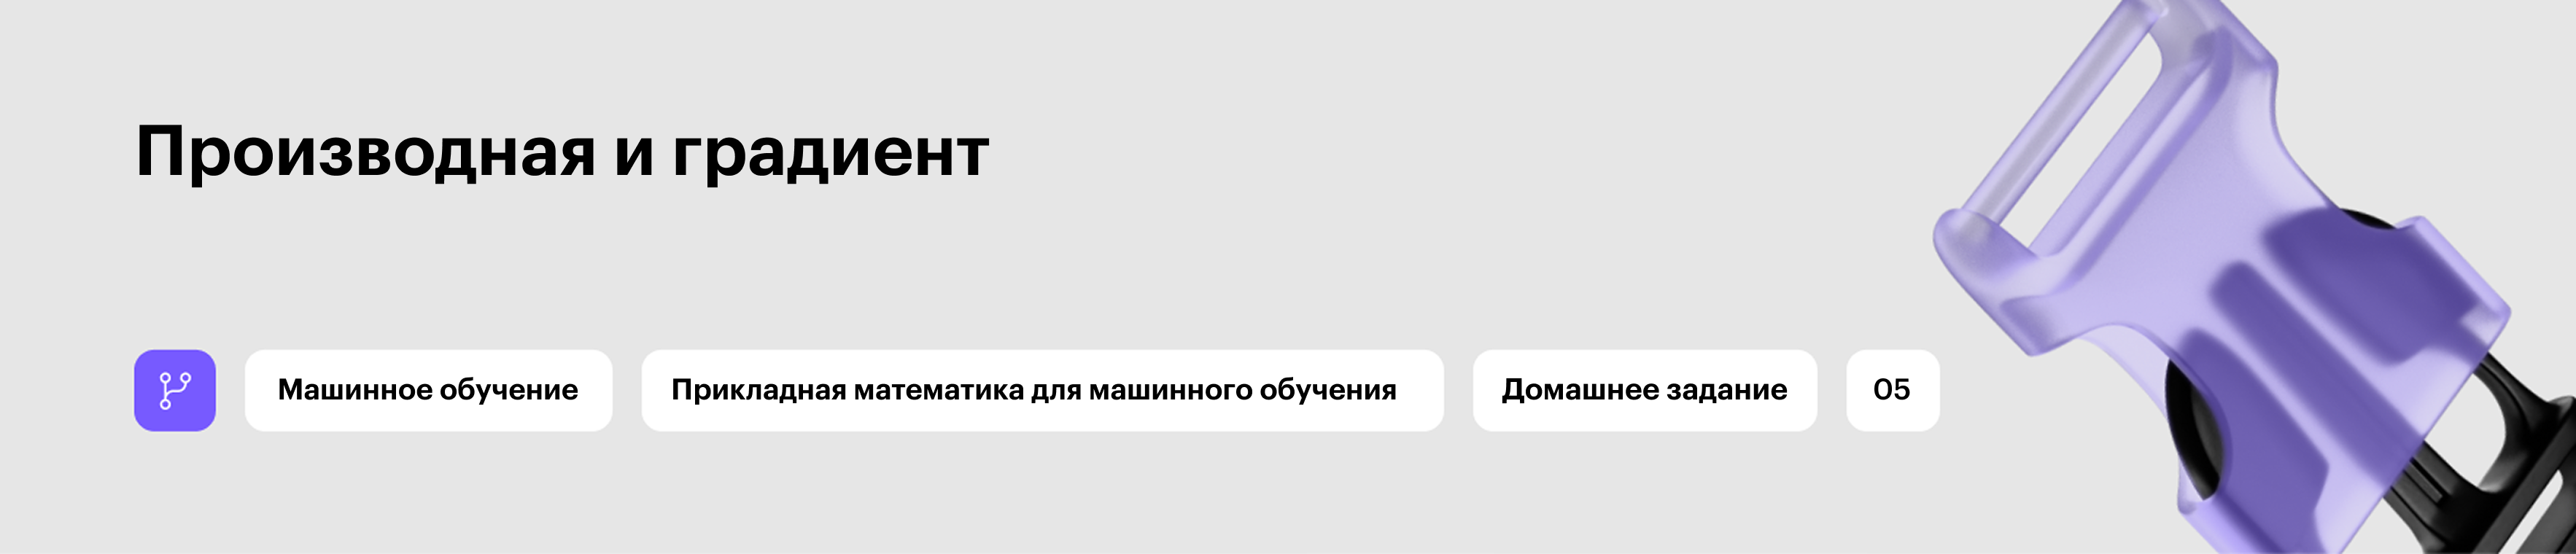

## Домашнее задание 5. Производная и градиент (4 балла + 1 бонус)

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

## <font color='DarkOrange'> **Задание 1 [2 балла]**</font>

С помощью численного представления производной убедитесь для каждой решенной  задачи (должна быть хотя бы 1 решенная задача) из домашней работы в правильности полученных вами формул градиента (матрицу Гессе проверять не нужно)

<font color='MediumTurquoise'>**Справка:**</font> Напомним, что одномерная производная по определению имеет вид:

$$f'(x) = \lim_{\Delta x \rightarrow 0} \frac{f(x + \Delta x) - f(x)}{\Delta x}$$

При численной оценке производной в формулу предела подставляется конкретное достаточно маленькое значение $\Delta x$ , например $\Delta x = 10^{-4}$

Для большей устойчивости численной оценки производной рекомендуется использовать формулу:

$$f(x) \approx \frac{f(x + \Delta x) - f(x - \Delta x)}{2 \Delta x}$$

Алгоритм проверки для функции $f(x)$, $x = (x_1, \dots, x_n)$



1.   Фиксируем $\Delta x$ и точку $x_0$
2.   Для каждого $i = 1 \dots n$
3.   $x_{up} = (x_1, \dots, x_{i - 1}, x_i + \Delta x, x_{i + 1}, \dots, x_n)$, $x_{down} = (x_1, \dots, x_{i - 1}, x_i - \Delta x, x_{i + 1}, \dots, x_n)$
4.   $grad[i] = \frac{f(x_{up}) - f(x_{down})}{2 \Delta x}$
5.   После цикла должно быть $\left.\nabla_x f\right|_{x = x_0} \approx grad$







In [1]:
import numpy as np

In [2]:
def numerical_gradient(f, x, h=1e-4):
    x = np.asarray(x, dtype=float)
    grad = np.zeros_like(x)

    for i in range(len(x)):
        x_up = x.copy()
        x_down = x.copy()

        x_up[i] += h
        x_down[i] -= h

        grad[i] = (f(x_up) - f(x_down)) / (2 * h)

    return grad


In [3]:
c = np.array([1.0, -2.0, 0.5])
a = np.array([-0.5, 1.5, 2.0])
sigma = 2.0


def f1(x):
    return np.linalg.norm(x)


def grad_f1(x):
    return x / np.linalg.norm(x)


def f2(x):
    return 1 / (1 + np.exp(-np.dot(c, x)))


def grad_f2(x):
    exp_value = np.exp(-np.dot(c, x))
    return exp_value / (1 + exp_value) ** 2 * c


def f3(x):
    return np.logaddexp(0, np.dot(a, x))


def grad_f3(x):
    return a / (1 + np.exp(-np.dot(a, x)))


def f4(x):
    return np.dot(c, x) + sigma / 3 * np.linalg.norm(x) ** 3


def grad_f4(x):
    return c + sigma * np.linalg.norm(x) * x


def f5(x):
    return np.dot(x, x) ** np.dot(x, x)


def grad_f5(x):
    return 2 * np.dot(x, x) ** np.dot(x, x) * (np.log(np.dot(x, x)) + 1) * x


In [4]:
points = [
    np.array([0.3, -0.4, 0.7]),
    np.array([-0.8, 0.2, 0.5]),
    np.array([1.0, 0.0, 0.0]),
]

functions = [
    (f1, grad_f1),
    (f2, grad_f2),
    (f3, grad_f3),
    (f4, grad_f4),
    (f5, grad_f5),
]

for number, (f, grad_f) in enumerate(functions, start=1):
    print("Задача", number)
    print()

    for x in points:
        grad_formula = grad_f(x)
        grad_numeric = numerical_gradient(f, x)

        print("x =", x)
        print("Градиент по формуле:", grad_formula)
        print("Численный градиент: ", grad_numeric)
        print("Совпадают:", np.allclose(grad_formula, grad_numeric, atol=1e-6))
        print()

    print()


Задача 1

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [ 0.34874292 -0.46499055  0.81373347]
Численный градиент:  [ 0.34874291 -0.46499055  0.81373347]
Совпадают: True

x = [-0.8  0.2  0.5]
Градиент по формуле: [-0.82956136  0.20739034  0.51847585]
Численный градиент:  [-0.82956135  0.20739034  0.51847585]
Совпадают: True

x = [1. 0. 0.]
Градиент по формуле: [1. 0. 0.]
Численный градиент:  [1. 0. 0.]
Совпадают: True


Задача 2

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [ 0.15390097 -0.30780194  0.07695049]
Численный градиент:  [ 0.15390097 -0.30780194  0.07695049]
Совпадают: True

x = [-0.8  0.2  0.5]
Градиент по формуле: [ 0.20110808 -0.40221616  0.10055404]
Численный градиент:  [ 0.20110808 -0.40221616  0.10055404]
Совпадают: True

x = [1. 0. 0.]
Градиент по формуле: [ 0.19661193 -0.39322387  0.09830597]
Численный градиент:  [ 0.19661193 -0.39322387  0.09830597]
Совпадают: True


Задача 3

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [-0.32850523  0.98551569  1.31402093]
Численный градиент

## <font color='DarkOrange'> **Задание 2 [2 балла]**</font>

С помощью автодифференцирования убедитесь для каждой решенной  задачи (должна быть хотя бы 1 решенная задача) из домашней работы в правильности полученных вами формул градиента (матрицу Гессе проверять не нужно)


In [5]:
import torch

In [6]:
c_torch = torch.tensor(c, dtype=torch.float64)
a_torch = torch.tensor(a, dtype=torch.float64)


def f1_torch(x):
    return torch.linalg.vector_norm(x)


def f2_torch(x):
    return 1 / (1 + torch.exp(-torch.dot(c_torch, x)))


def f3_torch(x):
    return torch.log1p(torch.exp(torch.dot(a_torch, x)))


def f4_torch(x):
    return torch.dot(c_torch, x) + sigma / 3 * torch.linalg.vector_norm(x) ** 3


def f5_torch(x):
    return torch.dot(x, x) ** torch.dot(x, x)


In [7]:
functions_torch = [
    (f1_torch, grad_f1),
    (f2_torch, grad_f2),
    (f3_torch, grad_f3),
    (f4_torch, grad_f4),
    (f5_torch, grad_f5),
]

for number, (f_torch, grad_f) in enumerate(functions_torch, start=1):
    print("Задача", number)
    print()

    for point in points:
        x = torch.tensor(point, dtype=torch.float64, requires_grad=True)

        y = f_torch(x)
        y.backward()

        grad_auto = x.grad.detach().numpy()
        grad_formula = grad_f(point)

        print("x =", point)
        print("Градиент по формуле:", grad_formula)
        print("Автодифференцирование:", grad_auto)
        print("Совпадают:", np.allclose(grad_formula, grad_auto, atol=1e-6))
        print()

    print()


Задача 1

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [ 0.34874292 -0.46499055  0.81373347]
Автодифференцирование: [ 0.34874292 -0.46499055  0.81373347]
Совпадают: True

x = [-0.8  0.2  0.5]
Градиент по формуле: [-0.82956136  0.20739034  0.51847585]
Автодифференцирование: [-0.82956136  0.20739034  0.51847585]
Совпадают: True

x = [1. 0. 0.]
Градиент по формуле: [1. 0. 0.]
Автодифференцирование: [1. 0. 0.]
Совпадают: True


Задача 2

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [ 0.15390097 -0.30780194  0.07695049]
Автодифференцирование: [ 0.15390097 -0.30780194  0.07695049]
Совпадают: True

x = [-0.8  0.2  0.5]
Градиент по формуле: [ 0.20110808 -0.40221616  0.10055404]
Автодифференцирование: [ 0.20110808 -0.40221616  0.10055404]
Совпадают: True

x = [1. 0. 0.]
Градиент по формуле: [ 0.19661193 -0.39322387  0.09830597]
Автодифференцирование: [ 0.19661193 -0.39322387  0.09830597]
Совпадают: True


Задача 3

x = [ 0.3 -0.4  0.7]
Градиент по формуле: [-0.32850523  0.98551569  1.31402093]
Автоди

## <font color='MediumSeaGreen'> **Задание 3 [бонус, 0.5 балла за задачу]**</font>

Выберите одну любую решенную задачу из домашней работы. С помощью численного представления производной, либо с помощью автодифференцирования (выберите то, что больше понравилось) проверьте правильность получившейся формулы для матрицы Гессе.

В случае выбора численного представления производной кратко опишите формулу, по которой будете считать приближенную матрицу

In [8]:
# Проверим Гессиан f(x) = ||x|| при x != 0.
def hessian_f1(x):
    norm = np.linalg.norm(x)

    return np.eye(len(x)) / norm - np.outer(x, x) / norm ** 3


for point in points:
    x = torch.tensor(point, dtype=torch.float64, requires_grad=True)

    hessian_auto = torch.autograd.functional.hessian(f1_torch, x).detach().numpy()
    hessian_formula = hessian_f1(point)

    print("x =", point)
    print("Гессиан по формуле:")
    print(hessian_formula)
    print()

    print("Автодифференцирование:")
    print(hessian_auto)
    print()

    print("Совпадают:", np.allclose(hessian_formula, hessian_auto, atol=1e-6))
    print()


x = [ 0.3 -0.4  0.7]
Гессиан по формуле:
[[ 1.02109412  0.18850968 -0.32989195]
 [ 0.18850968  0.91113014  0.43985593]
 [-0.32989195  0.43985593  0.39272851]]

Автодифференцирование:
[[ 1.02109412  0.18850968 -0.32989195]
 [ 0.18850968  0.91113014  0.43985593]
 [-0.32989195  0.43985593  0.39272851]]

Совпадают: True

x = [-0.8  0.2  0.5]
Гессиан по формуле:
[[ 0.32335053  0.17840029  0.44600073]
 [ 0.17840029  0.99235162 -0.11150018]
 [ 0.44600073 -0.11150018  0.75820124]]

Автодифференцирование:
[[ 0.32335053  0.17840029  0.44600073]
 [ 0.17840029  0.99235162 -0.11150018]
 [ 0.44600073 -0.11150018  0.75820124]]

Совпадают: True

x = [1. 0. 0.]
Гессиан по формуле:
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Автодифференцирование:
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Совпадают: True

